In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score, recall_score, precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

### Load data

In [ ]:
from google.colab import drive
root_drive='/content/drive'
drive.mount(root_drive, force_remount=True)

Mounted at /content/drive


In [ ]:
df = pd.read_csv('/content/drive/MyDrive/KhoaLuan/Data/df_cleaned_old_customers.csv', nrows=None)

In [ ]:
df = df.drop(columns=['Unnamed: 0'])
print("Dữ liệu có dạng:", df.shape)
df.head()

Dữ liệu có dạng: (291057, 29)


,TARGET,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,PREV_AMT_ANNUITY_MEAN,PREV_CNT_PAYMENT_SUM,...,AGE_GROUP,YEARS_REGISTRATION,YEARS_ID_PUBLISH,YEARS_EMPLOYED,YEARS_LAST_PHONE_CHANGE,BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS,BURO_DAYS_CREDIT_MEAN_YEARS,BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS,PREV_DAYS_DECISION_MAX_YEARS,INST_DAYS_ENTRY_PAYMENT_MAX_YEARS
0,1.0,0.1617,202500.0,406597.5,24700.5,49156.2,108131.945,1681.0289,9251.775,24.0,...,25-34,10,6,2.0,3,1.0,2.4,1.4,1.7,0.1
1,0.0,0.4668,270000.0,1293502.5,35698.5,0.0,254350.120,0.0000,56553.990,30.0,...,45-54,3,1,3.0,2,1.5,3.8,2.2,2.0,1.5
2,0.0,0.6426,67500.0,135000.0,6750.0,0.0,94518.900,0.0000,5357.250,4.0,...,45-54,12,7,1.0,2,1.3,2.4,1.5,2.2,2.0
3,0.0,0.6504,135000.0,312682.5,29686.5,44971.6,194400.000,0.0000,23651.174,138.0,...,45-54,27,7,8.0,2,0.4,2.9,1.3,0.5,0.0
4,0.0,0.3228,121500.0,513000.0,21865.5,0.0,146250.000,0.0000,12278.805,124.0,...,55-64,12,9,8.0,3,2.1,3.1,2.1,1.0,0.0


### Split tập train/test trước khi xử lý dữ liệu

In [ ]:
# Tách X, y
X = df.drop(columns=["TARGET"])
y = df["TARGET"]

# Chia tập train/test
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

### Pre-processing

In [ ]:
# Xác định loại biến
numeric_features = X_train_raw.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train_raw.select_dtypes(include=['object', 'category']).columns.tolist()

# Pipeline cho số
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

# Pipeline cho phân loại
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

# Kết hợp
preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])

### Model Predict XGBoost

In [ ]:
# Tính scale_pos_weight để xử lý mất cân bằng
scale_pos_weight = len(y_train[y_train == 0]) / len(y_train[y_train == 1])

xgb_model = XGBClassifier(
    objective='binary:logistic',
    eval_metric='auc',
    use_label_encoder=False,
    random_state=42,
    scale_pos_weight=scale_pos_weight,
    tree_method="hist",  # Tối ưu tốc độ cho tập lớn
)

In [ ]:
pipeline = ImbPipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', xgb_model)
])
param_grid = {
    'classifier__n_estimators': [300],
    'classifier__learning_rate': [0.05],
    'classifier__max_depth': [6],
    'classifier__subsample': [0.8]
}

grid = GridSearchCV(
    pipeline,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=5,
    verbose=1,
    n_jobs=-1
)

grid.fit(X_train_raw, y_train)

Fitting 5 folds for each of 1 candidates, totalling 5 fits


/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [13:18:18] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['EXT_SOURCE_MEAN',
                                                                          'AMT_INCOME_TOTAL',
                                                                          'AMT_CREDIT',
                                                                          'AMT_ANNUITY',
                                                                          'BURO_AMT_CREDIT_SUM_DEBT_MEAN',
                                                                          'BURO_AMT_CREDIT_SUM_MEAN',
                                                                          'BURO_AMT_CREDIT_MAX_OVERDUE_MEAN',
                                                                          'PREV_AMT_ANNUITY_MEAN',
                                                                          'PREV...
                                                      max_leaves=None,
                                                      min_child_weight=None,
                                                      missing=nan,
                                                      monotone_constraints=None,
                                                      multi_strategy=None,
                                                      n_estimators=None,
                                                      n_jobs=None,
                                                      num_parallel_tree=None,
                                                      random_state=42, ...))]),
             n_jobs=-1,
             param_grid={'classifier__learning_rate': [0.05],
                         'classifier__max_depth': [6],
                         'classifier__n_estimators': [300],
                         'classifier__subsample': [0.8]},
             scoring='roc_auc', verbose=1)

In [ ]:
def find_best_threshold(model, X, y, thresholds=np.arange(0.1, 0.91, 0.01)):
    y_proba = model.predict_proba(X)[:, 1]
    best_thresh, best_f1 = 0.5, 0

    for thresh in thresholds:
        y_pred = (y_proba >= thresh).astype(int)
        f1 = f1_score(y, y_pred)
        if f1 > best_f1:
            best_f1, best_thresh = f1, thresh
    return round(best_thresh, 2), round(best_f1, 4)

# Tìm threshold
best_model = grid.best_estimator_
X_test_transformed = best_model.named_steps["preprocessor"].transform(X_test_raw)
best_thresh, best_f1 = find_best_threshold(best_model, X_test_raw, y_test)
print("Best threshold:", best_thresh, "with F1:", best_f1)


Best threshold: 0.66 with F1: 0.3193


## Explainable AI

In [ ]:
import shap

In [ ]:
# 1. Tạo explainer cho XGBoost
xgb_model_only = best_model.named_steps['classifier']
X_test_transformed = best_model.named_steps['preprocessor'].transform(X_test_raw)

### SHAP - SHapley Additive exPlanations


Giải thích bằng SHAP cho model XGBoost

In [ ]:
# Lấy feature names
def get_feature_names(column_transformer):
    output_features = []
    for name, transformer, features in column_transformer.transformers_:
        if hasattr(transformer, 'get_feature_names_out'):
            output_features.extend(transformer.get_feature_names_out(features))
        elif isinstance(transformer, Pipeline):
            last_step = transformer.steps[-1][1]
            if hasattr(last_step, 'get_feature_names_out'):
                output_features.extend(last_step.get_feature_names_out(features))
            else:
                output_features.extend(features)
        else:
            output_features.extend(features)
    return output_features

feature_names = get_feature_names(best_model.named_steps['preprocessor'])
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

In [ ]:
explainer = shap.TreeExplainer(xgb_model_only)

Tính giá trị SHAP


In [ ]:
shap_values = explainer.shap_values(X_test_df)

#### Global Interpretability (toàn cục)

Biểu đồ độ quan trọng trung bình (tổng quan)

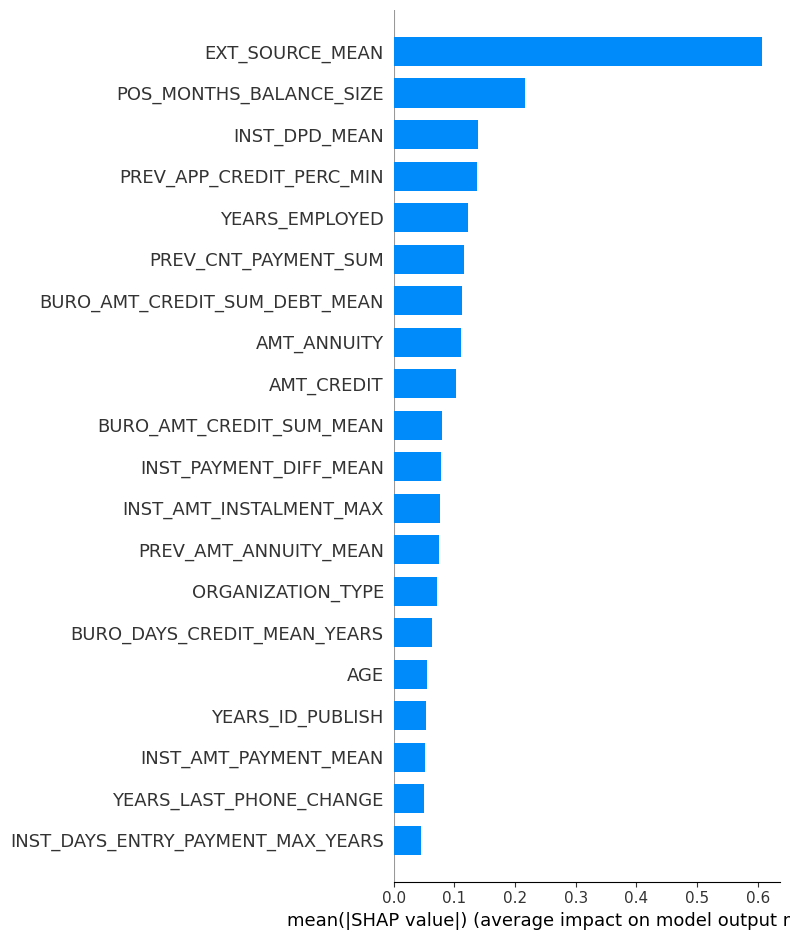

In [ ]:
shap.summary_plot(shap_values, X_test_df, plot_type="bar")

Biểu đồ phân bố chi tiết (beeswarm)

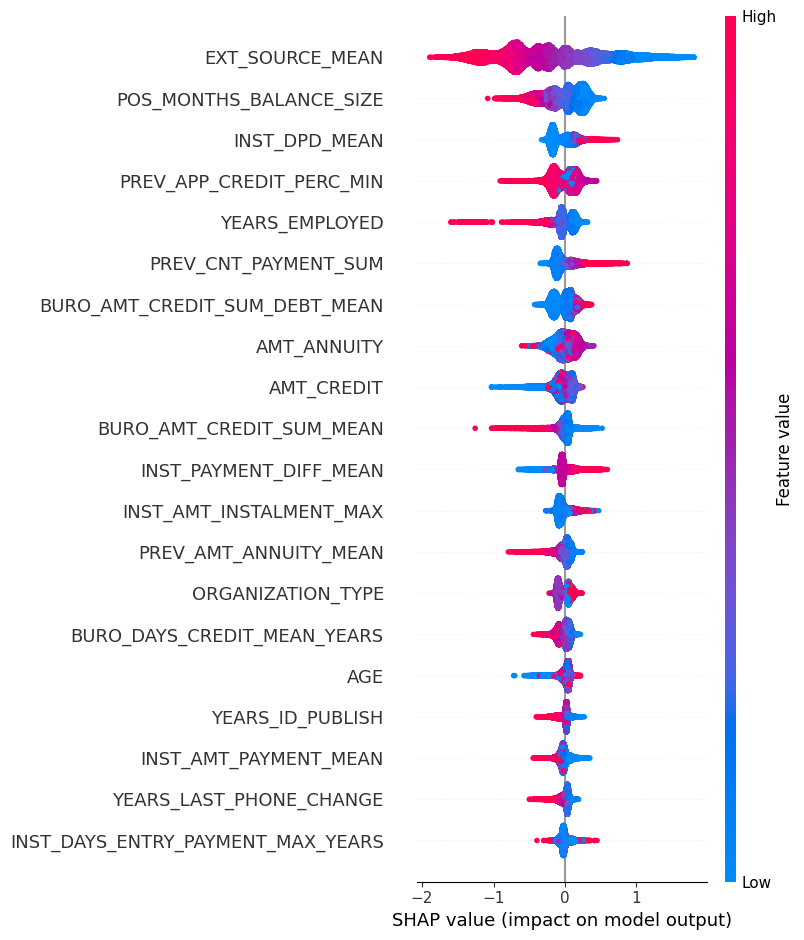

In [ ]:
shap.summary_plot(shap_values, X_test_df)

#### Local Interpretability (chi tiết từng cá nhân)

In [ ]:
i = 0  # ví dụ: khách hàng thứ nhất
X_test_df[i:i+1]

,EXT_SOURCE_MEAN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,BURO_AMT_CREDIT_SUM_DEBT_MEAN,BURO_AMT_CREDIT_SUM_MEAN,BURO_AMT_CREDIT_MAX_OVERDUE_MEAN,PREV_AMT_ANNUITY_MEAN,PREV_CNT_PAYMENT_SUM,PREV_APP_CREDIT_PERC_MIN,...,YEARS_EMPLOYED,YEARS_LAST_PHONE_CHANGE,BURO_DAYS_CREDIT_ENDDATE_MEAN_YEARS,BURO_DAYS_CREDIT_MEAN_YEARS,BURO_DAYS_CREDIT_UPDATE_MEAN_YEARS,PREV_DAYS_DECISION_MAX_YEARS,INST_DAYS_ENTRY_PAYMENT_MAX_YEARS,ORGANIZATION_TYPE,NAME_FAMILY_STATUS,AGE_GROUP
0,0.54,517500.0,1180129.5,34636.5,0.0,275550.0,607.5,69982.445,120.0,0.893815,...,4.0,1.0,-9.9,2.8,0.2,3.7,0.1,1.0,2.0,0.0


In [ ]:
i = 0  # ví dụ: khách hàng thứ nhất
# Use the fitted best_model (the pipeline) for prediction
y_pred_proba = best_model.predict_proba(X_test_raw.iloc[i:i+1])[:, 1] # Use X_test_raw as the pipeline handles preprocessing

# Use the best_thresh found earlier
y_pred = (y_pred_proba >= best_thresh).astype(int)
print("Probability of customer: ",y_pred_proba)
print("Prediction: ",y_pred)
print("Target: ",y_test.iloc[i])

Probability of customer:  [0.2400917]
Prediction:  [0]
Target:  0.0


Waterfall plot (một khách hàng)

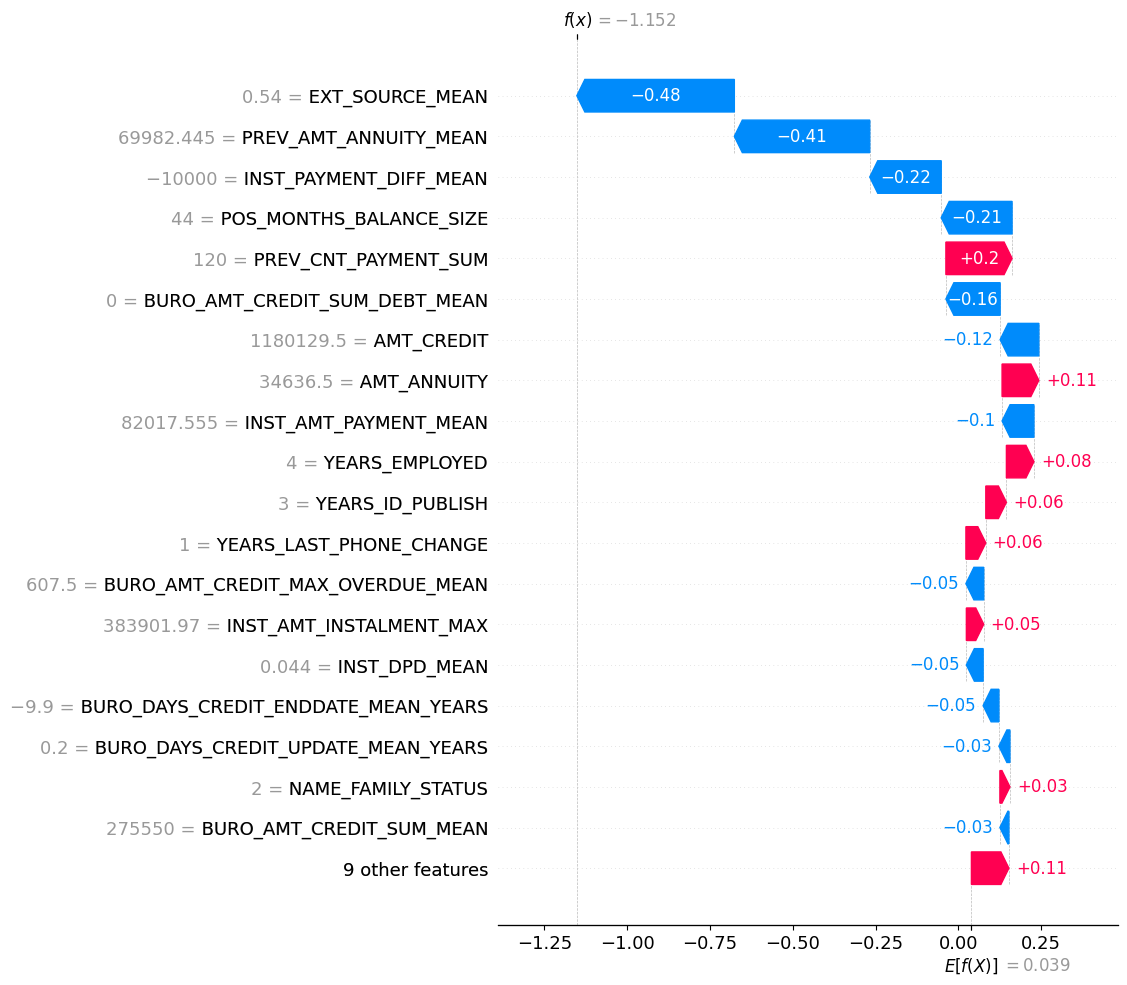

In [ ]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[i],
        base_values=explainer.expected_value,
        data=X_test_df.iloc[i]
    ),
    max_display=20
)

 Force plot (giải thích cụ thể)

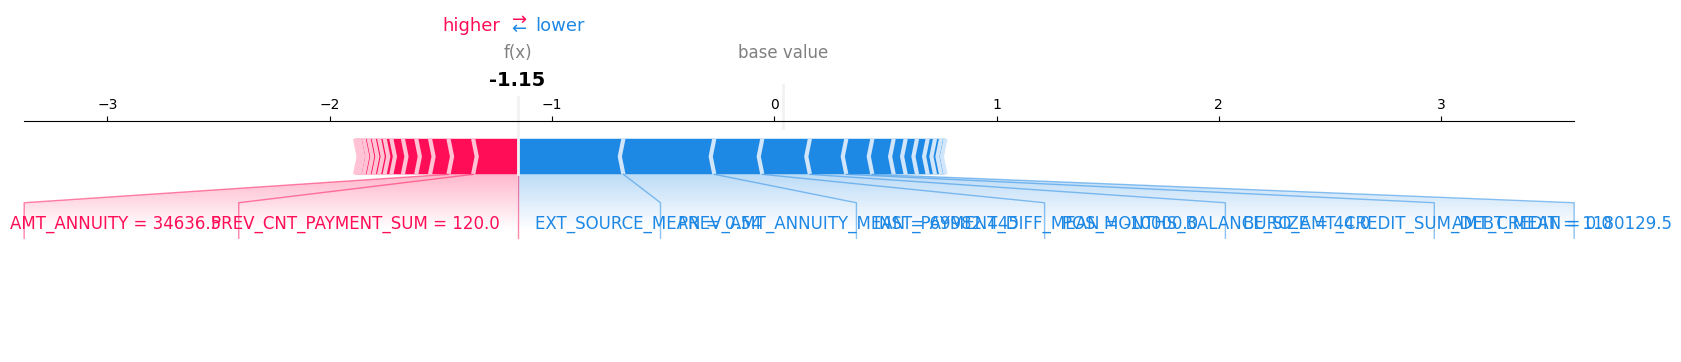

In [ ]:
# Làm tròn shap values và input values đến 3 chữ số
rounded_shap_values = np.round(shap_values[i], 3)
rounded_input = np.round(X_test_df.iloc[i], 3)

# Vẽ biểu đồ
shap.force_plot(
    explainer.expected_value,
    rounded_shap_values,
    rounded_input,
    matplotlib=True
)

####  Biểu đồ phụ thuộc (dependence plot)


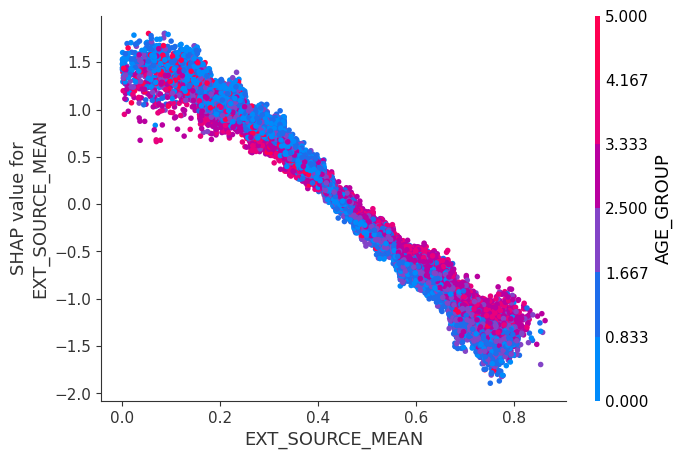

In [ ]:
shap.dependence_plot("EXT_SOURCE_MEAN", shap_values, X_test_df)

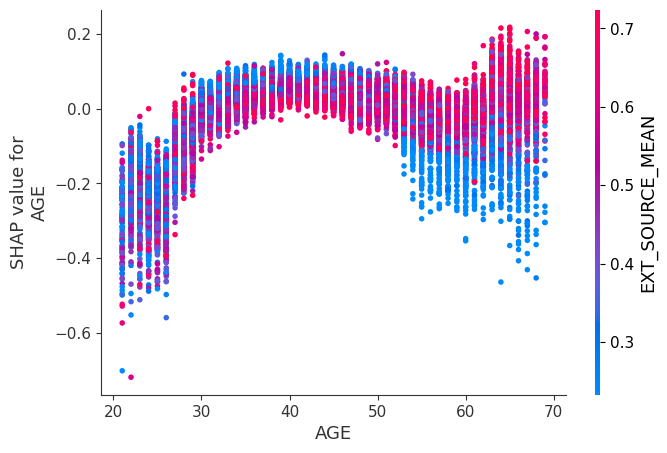

In [ ]:
shap.dependence_plot("AGE", shap_values, X_test_df)

### LIME - Local Interpretable Model-Agnostic Explanations)


In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=eff8c9de3e1c8815098bd1b1f29300073421afd3f9c170e0d4914fb356791008
  Stored in directory: /root/.cache/pip/wheels/85/fa/a3/9c2d44c9f3cd77cf4e533b58900b2bf4487f2a17e8ec212a3d
Successfully built lime


In [ ]:
import lime
from lime.lime_tabular import LimeTabularExplainer

In [ ]:
# Explainer yêu cầu dữ liệu numpy array
explainer_lime = LimeTabularExplainer(
    training_data=np.array(X_test_df),
    feature_names=feature_names,
    class_names=['No Default', 'Default'],
    mode='classification',
    discretize_continuous=True
)

In [ ]:
i = 0  # ví dụ: khách hàng thứ nhất
instance = X_test_df.iloc[i]  # Access the i-th row using iloc

# Dự đoán với model
# The LimeTabularExplainer's predict_fn needs to accept a 2D array
# The fitted pipeline handles preprocessing, so we should use the raw data here
model_predict_fn = lambda x: best_model.predict_proba(pd.DataFrame(x, columns=feature_names))

In [ ]:
print("Target thật của khách hàng thứ nhất là:", y_test.iloc[i])

Target thật của khách hàng thứ nhất là: 0.0


In [ ]:
lime_exp = explainer_lime.explain_instance(
    data_row=instance,
    predict_fn=model_predict_fn,
    num_features=10  # số feature muốn hiển thị
)

In [ ]:
lime_exp.show_in_notebook(show_table=True)

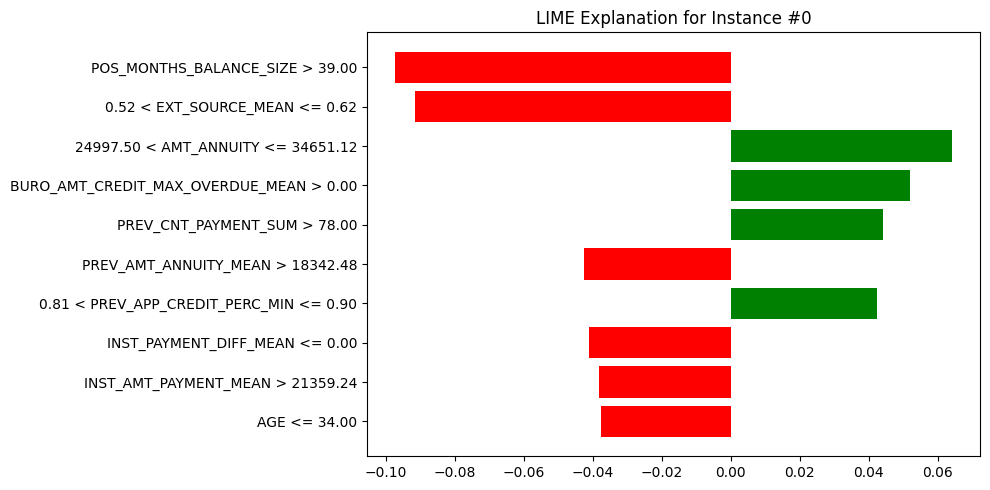

In [ ]:
fig = lime_exp.as_pyplot_figure()
fig.set_figwidth(10)
fig.set_figheight(5)
plt.title(f"LIME Explanation for Instance #{i}")
plt.tight_layout()
plt.show()